![Banner](../images/09_10_banner_rs_object_detection.png)


# Field Edge Detection in Sentinel-2: Fields of The World versus Delineate Anything

This notebook compares Fields of The World and Delineate Anything on Sentinel-2 imagery of the US Corn Belt, next to classical edge detectors, and scores them against field parcels derived from the Cropland Data Layer.


## Overview

Field boundaries are the unit of most agricultural statistics, insurance and advice, yet in many countries no field map exists. Two open model families now promise field boundaries anywhere from free Sentinel-2 imagery:

- **Fields of The World (FTW)** (Kerner et al., 2025; <https://fieldsofthe.world>) trains U-Nets with EfficientNet encoders on 24 countries. A model reads **two Sentinel-2 dates** (around planting and harvest, B04-B03-B02-B08 each) and labels every pixel *background*, *field* or *field boundary*; fields are the connected field pixels. The output follows the **fiboa** standard.
- **Delineate Anything** (Lavreniuk et al., 2025) is a YOLO11 **instance-segmentation** model trained on FBIS-22M, about 23 million field masks at 0.25-10 m. It reads **one RGB image** and returns one mask per field.

This notebook runs both on the US Corn Belt (`Data/08_remote_sensing/08_10_object_detection/Corn_belt`, north-central Iowa, 30 x 29 km) for 2024 and 2025, next to classical edge detectors, with the tools in `geolattice.rsense.edge_detectors`, and scores them against field parcels derived from the 10 m Cropland Data Layer (CDL):

| Step | Content | GeoLattice |
|---|---|---|
| 1 | Sentinel-2 dates of 2024 and 2025, CDL at 10 m | `rioxarray` |
| 2 | A field reference from the CDL (parcel proxies and boundaries) | `ed.rasterize_boundaries` |
| 3 | The FTW two-window input | `ed.ftw_stack` |
| 4 | One evaluation protocol: pixel boundary F1 and object (field) matching | `ed.edge_metrics`, `ic.polygon_iou` |
| 5 | Classical edge detectors (CPU) | `ed.classical_edges`, `ed.boundary_to_instances` |
| 6 | FTW models B3, B5, B7 and B5 CC-BY with the crop-calendar windows (GPU) | `ed.ftw_models`, `ed.load_ftw_model`, `ed.detect_fields_ftw` |
| 7 | FTW settings chosen on 2024, tested on 2025 | `ed.ftw_stack`, `ed.detect_fields_ftw` |
| 8 | Delineate Anything: DA-S, DA v1, DA v2 | `ed.load_delineate_anything`, `ed.detect_delineate_anything` |
| 9 | Results, maps and field sizes | |
| 10 | Year-to-year stability of the fields | |
| 11 | The best map as fiboa GeoParquet | `ed.to_fiboa` |


## Core concepts

### Learning objectives

1. Build a field reference from the Cropland Data Layer and score every method against it with the same protocol.
2. Prepare the Fields of The World input from two Sentinel-2 dates and run the released FTW models.
3. Run Delineate Anything on one RGB date and compare it with FTW and classical edge detectors.
4. Choose every setting on 2024 and apply it unchanged to 2025.
5. Read object F1, boundary F1, field size and year-to-year stability, including where models merge or split fields.
6. Export the best 2025 field map as fiboa GeoParquet and check the licence of each model.

### Contents

1. Rules of the comparison
2. Setup
3. Data
4. A field reference from the CDL
5. The FTW input: two windows per year
6. One evaluation protocol for every method
7. Classical edge detectors (CPU)
8. Fields of The World with the crop-calendar windows (GPU)
9. FTW settings chosen on 2024, tested on 2025
10. Delineate Anything
11. Results
12. Year-to-year stability
13. The best map as fiboa GeoParquet
14. Discussion


## Rules of the comparison

- **Selection year and test year.** Every choice (thresholds of the classical detectors, FTW windows and settings, Delineate Anything model, date and scale) is made on **2024** and applied unchanged to **2025**. Scores on 2025 are the test result.
- **No training.** All networks are used as released; nothing is fine-tuned on Iowa.
- **Hardware.** Steps 1-5 run on a CPU. Steps 6-8 use a GPU (one RTX A5500: about 10 s per model and year for this 883 km² AOI); on a CPU expect minutes per run.
- **Downloads.** The FTW checkpoints come from the FTW GitHub release through `ed.load_ftw_model(..., download=True)` and the Delineate Anything checkpoints from Hugging Face, about 0.8 GB in total, cached in `~/.cache/geolattice/` (set `RUN_DOWNLOAD = False` to use local files only). Licences: FTW standard models include CC-BY-NC-SA training data, the `_CCBY` models are CC-BY-4.0, Delineate Anything is AGPL-3.


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [ ]:
# Setup: libraries, GeoLattice modules, device, paths and the random seed.
import time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, xarray as xr, rioxarray
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage as ndi
from skimage.measure import label as cc_label
from rasterio import features as rfeat
from shapely.geometry import shape
import torch
import geolattice.rsense.edge_detectors as ed
import geolattice.rsense.classify.image_classification as ic

CANDIDATES = [Path("../../../../Data/08_remote_sensing/08_10_object_detection/Corn_belt"),
              Path("Data/08_remote_sensing/08_09_image_classification/Corn_belt")]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)
if DATA is None:
    raise FileNotFoundError("Run Jupyter from this notebook's folder or from the GeoLattice repository root.")
S2_DIR, CDL_DIR = DATA / "Sentinel_2", DATA / "CDL" / "10_m"
OUT = DATA / "outputs" / "field_edge_sentinel2"
OUT.mkdir(parents=True, exist_ok=True)
DA_CACHE = Path.home() / ".cache" / "geolattice" / "delineate_anything"     # Delineate Anything checkpoints
RUN_DOWNLOAD = True        # fetch missing FTW / Delineate Anything checkpoints (about 0.8 GB, once)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only: Steps 1-5 run fine, Steps 6-7 are slow")
SEED = 42
rng = np.random.default_rng(SEED)
YEARS = (2024, 2025)

torch 2.14.0+cu132 | device: cuda | NVIDIA RTX A5500 Laptop GPU


## Data

The Sentinel-2 folder holds one clear L2A image per month from May to October (the download kept scenes with at least 90 % of the AOI clear). The four FTW bands (red B04, green B03, blue B02, NIR B08) are read at 10 m; the scene classification layer masks clouds and shadows. The digital numbers have the L2A radiometric offset already removed (reflectance = DN / 10 000). The 10 m CDL of 2024 and 2025 (EPSG:5070) is put on the Sentinel-2 grid by nearest neighbour.


In [ ]:
# Step 1. The Sentinel-2 dates of 2024 and 2025 and the 10 m CDL on one grid.
inv = pd.read_csv(S2_DIR / "inventory.csv")
inv = inv[inv.status.eq("downloaded") & inv.year.isin(YEARS)][["year", "month", "date", "tiles", "scene_cloud_pct", "aoi_clear_frac", "folder"]]
print(inv.to_string(index=False))

BANDS = ["red", "green", "blue", "nir"]                # B04, B03, B02, B08: the FTW bands
def s2_window(folder):
    """The four 10 m FTW bands of one date in Sentinel-2 L2A digital numbers (offset already removed),
    with clouds, shadows and no data (scene classification layer) set to NaN."""
    p = S2_DIR / folder
    ref = rioxarray.open_rasterio(p / "red.tif").squeeze(drop=True)
    scl = rioxarray.open_rasterio(p / "scl.tif").squeeze(drop=True).rio.reproject_match(ref, resampling=0).values
    bad = np.isin(scl, [0, 1, 3, 8, 9, 10, 11])
    a = xr.concat([rioxarray.open_rasterio(p / f"{b}.tif").squeeze(drop=True).astype("float32") for b in BANDS], "band")
    a = a.assign_coords(band=BANDS).where(~xr.DataArray(bad, dims=("y", "x")) & (a > 0))
    return a.rio.write_crs(ref.rio.crs)

FOLDERS = dict(zip(pd.to_datetime(inv.date).dt.strftime("%Y-%m-%d"), inv.folder))
WIN = {d: s2_window(f) for d, f in FOLDERS.items()}
GRID = WIN[next(iter(WIN))].isel(band=0, drop=True)
H, W = GRID.shape
TRANSFORM, CRS = GRID.rio.transform(), GRID.rio.crs
print(f"\n{len(WIN)} dates on a {W} x {H} px grid at 10 m ({W * H * 1e-4:,.0f} km²), {CRS}")

# CDL 2024 and 2025 at 10 m (EPSG:5070) onto the Sentinel-2 grid, nearest neighbour
CDL = {y: rioxarray.open_rasterio(CDL_DIR / f"CDL_{y}_10m.tif").squeeze(drop=True).rio.reproject_match(GRID, resampling=0).values.astype("int16")
       for y in YEARS}
legend = pd.read_csv(CDL_DIR / "cdl_class_legend.csv").set_index("code")["class_name"]
share = pd.DataFrame({y: pd.Series(CDL[y][CDL[y] > 0]).map(legend).value_counts(normalize=True).head(8) * 100 for y in YEARS}).round(1)
print("\nCDL classes (% of labelled pixels):"); print(share.fillna(0))

 year  month       date tiles  scene_cloud_pct  aoi_clear_frac           folder
 2024      5 2024-05-18 15TVH             4.50          0.9992 2024_05_20240518
 2024      6 2024-06-14 15TVH             0.00          0.9995 2024_06_20240614
 2024      7 2024-07-12 15TVH             1.72          0.9530 2024_07_20240712
 2024      8 2024-08-31 15TVH             0.00          0.9997 2024_08_20240831
 2024      9 2024-09-30 15TVH             0.00          1.0000 2024_09_20240930
 2024     10 2024-10-05 15TVH             0.00          1.0000 2024_10_20241005
 2025      5 2025-05-08 15TVH             4.73          0.9992 2025_05_20250508
 2025      6 2025-06-22 15TVH             0.07          0.9993 2025_06_20250622
 2025      7 2025-07-14 15TVH             0.35          0.9989 2025_07_20250714
 2025      8 2025-08-26 15TVH             2.60          0.9972 2025_08_20250826
 2025      9 2025-09-27 15TVH             0.00          1.0000 2025_09_20250927
 2025     10 2025-10-10 15TVH           


12 dates on a 3032 x 2911 px grid at 10 m (883 km²), EPSG:32615



CDL classes (% of labelled pixels):
                         2024  2025
Corn                     48.8  52.7
Soybeans                 40.8  36.4
Grassland/Pasture         4.8   3.9
Developed/Open Space      2.4   2.4
Developed/Low Intensity   1.0   1.7
Herbaceous Wetlands       0.4   0.9
Woody Wetlands            0.4   0.5
Developed/Med Intensity   0.3   0.3


All twelve dates are almost cloud-free (95-100 % of the AOI clear). Corn and soybeans cover about 90 % of the labelled land in both years.

## A field reference from the CDL

There are no digitised field boundaries for this AOI, so we build **parcel proxies** from the CDL:

1. **Cropland** is any cultivated CDL class in both years; grass/pasture, developed land (including the 1-pixel roads of the CDL), forest, wetland and water are not fields.
2. Each pixel's crop is taken from a **5 x 5 majority-filtered** CDL, which removes the per-pixel speckle inside fields, while the cropland mask comes from the original CDL so that roads keep separating fields.
3. A **parcel** is a 4-connected group of cropland pixels with the same **(2024, 2025) crop pair**. With the corn-soybean rotation, most neighbouring fields differ in at least one year (only 15 % of cropland has the same crop in both years); roads and farmsteads separate the rest. Parcels below 2 ha (mostly classification noise at field edges) are dropped and holes (ponds, speckle) filled.
4. The **boundary reference** is each parcel outline buffered by 5 m (a band about two pixels wide), rasterised with `ed.rasterize_boundaries`; pixels inside a parcel or on its boundary band are scored.

This reference has known limits: two neighbouring fields with the same crop in both years merge into one parcel, and a field split between two crops (strip trials, a replanted part) becomes two. It measures agreement with the CDL's view of the fields, not with a cadastre.


1,412 reference parcels (≥ 2.0 ha): median 34.9 ha, mean 55.0 ha, largest 424 ha; 88% of the grid
scored pixels: 92% of the grid; boundary share of the scored pixels 10.8%
cropland pixels with the same crop in both years (merge risk for neighbours): 15%


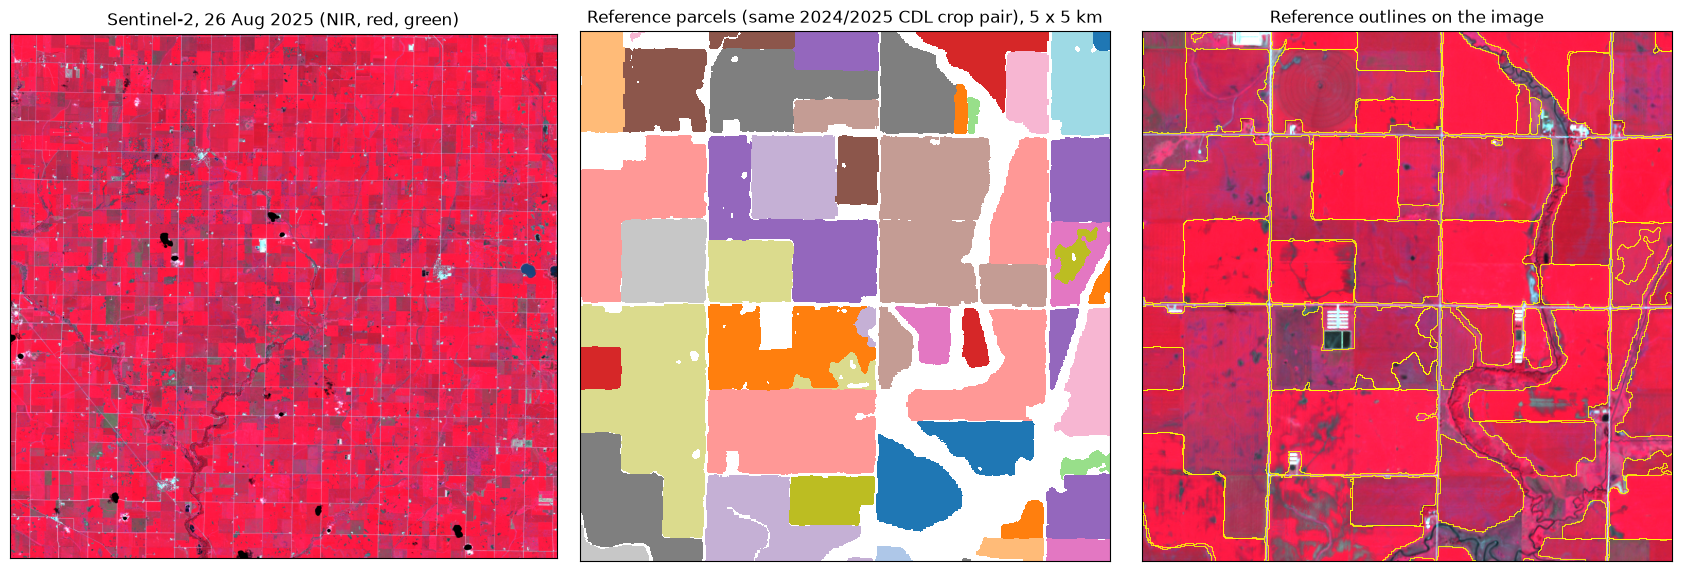

In [ ]:
# Step 2. A field reference from the CDL: parcel proxies and their boundaries.
from shapely.geometry import Polygon
# Cropland = cultivated CDL codes (1-60, 66-80, 200-255); grass/pasture, developed, forest, wetland and water are not fields.
def cropland(c):
    return ((c >= 1) & (c <= 60)) | ((c >= 66) & (c <= 80)) | (c >= 200)
# The CDL is a per-pixel classification with speckle inside fields. The crop of each pixel is taken from a 5 x 5
# majority-filtered CDL (removes speckle), but the cropland mask from the original CDL, which keeps the 1-pixel
# roads and farmsteads that separate fields (a majority filter would erase them).
from skimage.filters.rank import majority
from skimage.morphology import footprint_rectangle
CDLS = {y: majority(np.clip(CDL[y], 0, 255).astype("uint8"), footprint_rectangle((5, 5))).astype("int16") for y in YEARS}
CROP = cropland(CDL[2024]) & cropland(CDL[2025]) & cropland(CDLS[2024]) & cropland(CDLS[2025])

# A parcel proxy: connected cropland pixels with the same (2024, 2025) crop pair. The corn-soybean rotation makes
# most neighbouring fields differ in at least one year; roads and farmsteads (developed) separate the rest.
pair = np.where(CROP, CDLS[2024].astype("int32") * 1000 + CDLS[2025], -1)
lab = cc_label(pair + 1, background=0, connectivity=1)
MIN_HA = 2.0                                            # smaller pieces are mostly CDL noise at field edges
size = np.bincount(lab.ravel())
keep = np.flatnonzero(size >= MIN_HA * 100); keep = keep[keep > 0]
PARCELS = np.where(np.isin(lab, keep), lab, 0).astype("int32")
REF = gpd.GeoDataFrame({"ref_id": [int(v) for _, v in rfeat.shapes(PARCELS, mask=PARCELS > 0, transform=TRANSFORM, connectivity=4)]},
                       geometry=[shape(g) for g, _ in rfeat.shapes(PARCELS, mask=PARCELS > 0, transform=TRANSFORM, connectivity=4)], crs=CRS)
REF = REF.dissolve("ref_id").reset_index()
REF["geometry"] = REF.geometry.apply(lambda g: Polygon(g.exterior) if g.geom_type == "Polygon" else g)   # fill holes (farm ponds, speckle)
REF["area_ha"] = REF.area / 1e4
# boundary reference: parcel outlines buffered by 5 m (a band about two 10 m pixels wide); scored pixels = inside a
# parcel or on its boundary band
TRUTH, VALID = ed.rasterize_boundaries(REF, transform=TRANSFORM, shape=(H, W), buffer=5.0, return_valid=True)
TRUTH, VALID = TRUTH.astype(bool), VALID.astype(bool)
print(f"{len(REF):,} reference parcels (≥ {MIN_HA} ha): median {REF.area_ha.median():.1f} ha, mean {REF.area_ha.mean():.1f} ha, "
      f"largest {REF.area_ha.max():.0f} ha; {PARCELS.astype(bool).mean():.0%} of the grid")
print(f"scored pixels: {VALID.mean():.0%} of the grid; boundary share of the scored pixels {TRUTH[VALID].mean():.1%}")
same_pair = (CDLS[2024] == CDLS[2025])[CROP].mean()
print(f"cropland pixels with the same crop in both years (merge risk for neighbours): {same_pair:.0%}")

def false_colour(a, lo=(0, 0, 0), hi=(4500, 1800, 1500)):
    # NIR, red, green: crops bright red, bare soil cyan-grey
    im = np.dstack([a.sel(band=b).values for b in ("nir", "red", "green")])
    return np.clip((np.nan_to_num(im) - lo) / np.array(hi), 0, 1)
EXT = [float(GRID.x.min()) - 5, float(GRID.x.max()) + 5, float(GRID.y.min()) - 5, float(GRID.y.max()) + 5]
Z = (slice(1200, 1700), slice(1300, 1800))                  # a 5 x 5 km zoom used in all figures
ZEXT = [EXT[0] + Z[1].start * 10, EXT[0] + Z[1].stop * 10, EXT[3] - Z[0].stop * 10, EXT[3] - Z[0].start * 10]
fig, ax = plt.subplots(1, 3, figsize=(17, 5.6))
ax[0].imshow(false_colour(WIN["2025-08-26"]), extent=EXT); ax[0].set_title("Sentinel-2, 26 Aug 2025 (NIR, red, green)")
ax[1].imshow(np.where(PARCELS > 0, PARCELS % 20, np.nan)[Z], cmap="tab20", extent=ZEXT, interpolation="nearest")
ax[1].set_title("Reference parcels (same 2024/2025 CDL crop pair), 5 x 5 km")
ax[2].imshow(false_colour(WIN["2025-08-26"])[Z], extent=ZEXT); REF.cx[ZEXT[0]:ZEXT[1], ZEXT[2]:ZEXT[3]].boundary.plot(ax=ax[2], color="yellow", lw=0.6)
ax[2].set_xlim(ZEXT[0], ZEXT[1]); ax[2].set_ylim(ZEXT[2], ZEXT[3]); ax[2].set_title("Reference outlines on the image")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## The FTW input: two windows per year

FTW models expect 8 bands: B04, B03, B02, B08 of **window A** (around planting) followed by the same bands of **window B** (around harvest), in Sentinel-2 L2A digital numbers. The FTW CLI picks the two dates from the USDA crop calendar; for Iowa that means May and October. `ed.ftw_stack` builds the stack from two `(band, y, x)` arrays (band names `red`, `green`, `blue`, `nir` or `B04`...) and keeps the georeference.


ftw_stack: (8, 2911, 3032) [np.str_('B04_A'), np.str_('B03_A'), np.str_('B02_A'), np.str_('B08_A'), np.str_('B04_B'), np.str_('B03_B'), np.str_('B02_B'), np.str_('B08_B')] | CRS EPSG:32615 | NaN (cloud) share 0.00%


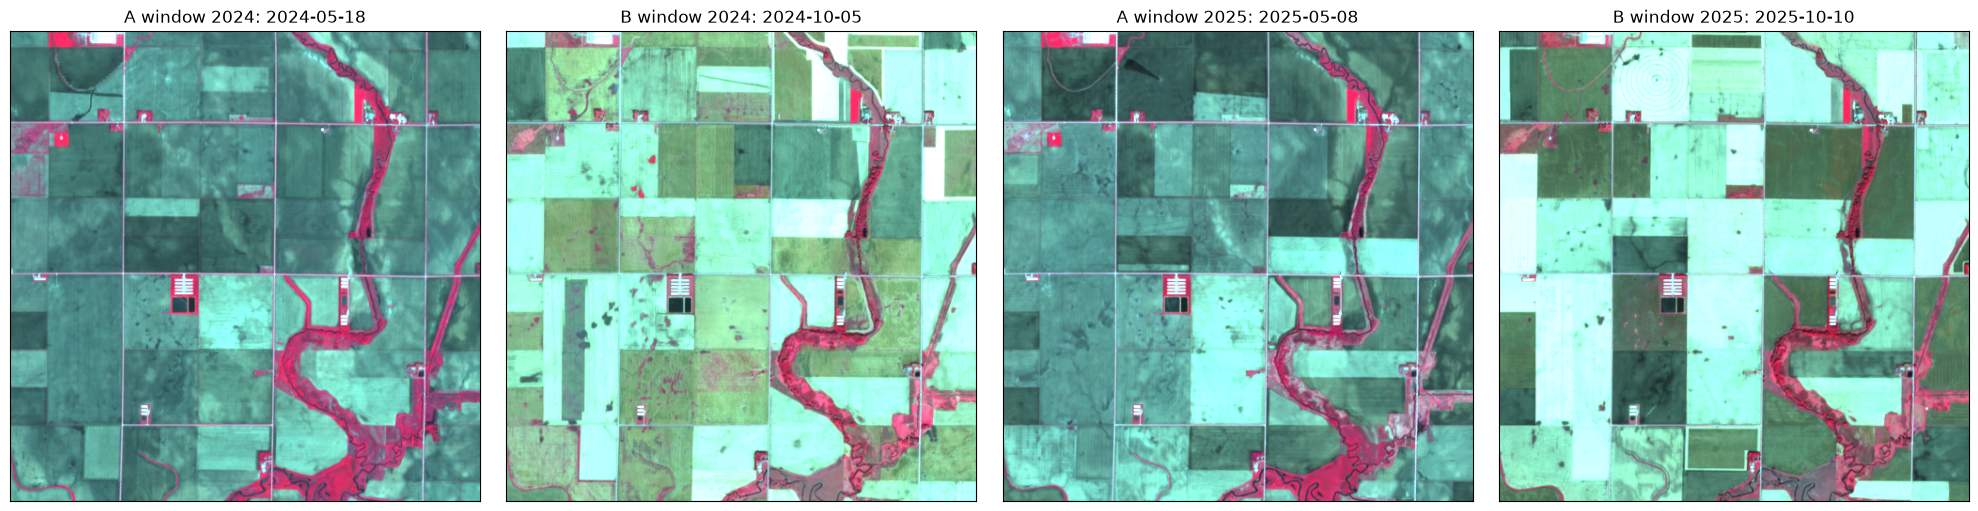

In [ ]:
# Step 3. FTW input: two windows per year, B04-B03-B02-B08 each, stacked with ed.ftw_stack.
# Window A around planting (May), window B around harvest (October), from the USDA crop calendar for Iowa.
PAIRS = {2024: ("2024-05-18", "2024-10-05"), 2025: ("2025-05-08", "2025-10-10")}
STACK = {y: ed.ftw_stack(WIN[a], WIN[b]) for y, (a, b) in PAIRS.items()}
s = STACK[2025]
print("ftw_stack:", tuple(s.shape), list(s.band.values), "| CRS", s.rio.crs, "| NaN (cloud) share", f"{np.isnan(s.values).any(0).mean():.2%}")
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for i, (y, d) in enumerate([(y, d) for y in YEARS for d in PAIRS[y]]):
    ax[i].imshow(false_colour(WIN[d])[Z], extent=ZEXT); ax[i].set_title(f"{'A' if d == PAIRS[y][0] else 'B'} window {y}: {d}")
    ax[i].set_xticks([]); ax[i].set_yticks([])
plt.tight_layout(); plt.show()

In May both crops are bare soil or seedlings, so neighbouring corn and soybean fields look alike; in October many fields are harvested at different times. This matters for which boundaries the model can see (Step 7).

## One evaluation protocol for every method

Each method produces **field polygons**. Two complementary scores:

**Pixel boundary score.** Predicted boundary pixels against the reference boundary band, with `ed.edge_metrics` (precision, recall and F1 of the boundary class over the scored pixels), exactly and with a tolerance of one pixel (10 m), because a boundary drawn one pixel to the side of a hand-made or CDL-derived line is not an error in practice. For FTW, every pixel that is not *field* (boundary or background: FTW calls roads background) counts as boundary; for the polygon methods, the polygon outlines; for classical detectors, the thresholded edge map.

**Object (field) score.** Predicted fields of at least 2 ha (the reference minimum) whose centre lies in the scored area are matched one-to-one with reference parcels, greedily by decreasing intersection over union (IoU, computed with `ic.polygon_iou` on candidate pairs from a spatial index). A match needs IoU ≥ 0.5:

$$
\text{precision}=\frac{TP}{N_{\text{pred}}},\qquad \text{recall}=\frac{TP}{N_{\text{ref}}},\qquad F_1=\frac{2\,\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}} .
$$

Two error types are reported separately: **over-segmented references** (share of reference parcels split into two or more predictions that each lie mostly inside them) and **merged predictions** (share of predictions overlapping two or more reference parcels with IoU > 0.1). The median, over reference parcels, of the best IoU of any prediction summarises shape agreement.


In [ ]:
# Step 4. One evaluation protocol for every method.
RESULTS, MAPS = [], {}

def boundary_map(fields):
    """1-pixel outlines of predicted polygons on the grid (how polygon methods are scored as boundaries)."""
    if not len(fields):
        return np.zeros((H, W), bool)
    return rfeat.rasterize(((g.boundary, 1) for g in fields.geometry), out_shape=(H, W), transform=TRANSFORM,
                           fill=0, all_touched=True, dtype="uint8").astype(bool)

def match_objects(pred, ref=REF, iou_min=0.5):
    """One-to-one matching of predicted to reference parcels by IoU (candidate pairs from a spatial index,
    IoU with ic.polygon_iou). Only predictions of at least MIN_HA (the reference minimum) with their centre in
    the scored area are counted."""
    pred = pred[pred.area >= MIN_HA * 1e4].reset_index(drop=True)
    if len(pred):
        from rasterio.transform import rowcol
        pts = pred.geometry.representative_point()
        r, c = rowcol(TRANSFORM, pts.x.to_numpy(), pts.y.to_numpy())
        r, c = np.clip(r, 0, H - 1), np.clip(c, 0, W - 1)
        pred = pred[VALID[r, c]].reset_index(drop=True)
    pairs = gpd.sjoin(pred[["geometry"]].reset_index(names="p"), ref[["geometry"]].reset_index(names="r"), predicate="intersects")
    iou = np.array([ic.polygon_iou([pred.geometry.iloc[p]], [ref.geometry.iloc[r]])[0, 0] for p, r in zip(pairs.p, pairs.r)])
    pairs = pairs.assign(iou=iou).sort_values("iou", ascending=False)
    used_p, used_r, tp = set(), set(), 0
    for p, r, v in zip(pairs.p, pairs.r, pairs.iou):
        if v < iou_min:
            break
        if p not in used_p and r not in used_r:
            used_p.add(p); used_r.add(r); tp += 1
    best_ref = pairs.groupby("r").iou.max().reindex(range(len(ref))).fillna(0)
    # over-segmentation: a reference parcel split into >= 2 predictions that each lie mostly inside it
    inside = pairs.assign(frac=[pred.geometry.iloc[p].intersection(ref.geometry.iloc[r]).area / pred.geometry.iloc[p].area for p, r in zip(pairs.p, pairs.r)])
    over = (inside[inside.frac > 0.5].groupby("r").size() >= 2).mean() if len(inside) else 0
    under = (pairs[pairs.iou > 0.1].groupby("p").size() >= 2).mean() if len(pairs) else 0
    n_p, n_r = len(pred), len(ref)
    prec, rec = (tp / n_p if n_p else 0), tp / n_r
    return {"fields": n_p, "object precision": prec, "object recall": rec,
            "object F1": 2 * prec * rec / (prec + rec) if prec + rec else 0,
            "median best IoU": float(best_ref.median()), "over-segmented refs": float(over), "merged preds": float(under)}

def evaluate(name, year, fields, *, kind, boundary_score=None, seconds=None, **extra):
    """Pixel boundary metrics (exact and with 1 px tolerance) and object metrics for one method and year."""
    score = boundary_map(fields).astype(float) if boundary_score is None else boundary_score
    px0 = ed.edge_metrics(score, TRUTH, valid=VALID, threshold=0.5)
    px1 = ed.edge_metrics(score, TRUTH, valid=VALID, threshold=0.5, tolerance=1)
    row = {"method": name, "kind": kind, "year": year, "boundary F1": px0["boundary_f1"], "boundary F1 (±1 px)": px1["boundary_f1"],
           **match_objects(fields), "median area (ha)": float(fields.area.median() / 1e4) if len(fields) else np.nan,
           "seconds": seconds, **extra}
    RESULTS[:] = [r for r in RESULTS if not (r["method"] == name and r["year"] == year)]   # re-running replaces
    RESULTS.append(row); MAPS[(name, year)] = fields
    return row

def table(rows=None):
    df = pd.DataFrame(rows or RESULTS)
    cols = ["kind", "method", "year", "fields", "boundary F1", "boundary F1 (±1 px)", "object precision", "object recall",
            "object F1", "median best IoU", "over-segmented refs", "merged preds", "median area (ha)", "seconds"]
    return df[[c for c in cols if c in df]].round(3)

ref_row = match_objects(REF)
print("sanity check, reference against itself:", {k: round(v, 3) for k, v in ref_row.items()})

sanity check, reference against itself: {'fields': 1412, 'object precision': 1.0, 'object recall': 1.0, 'object F1': 1.0, 'median best IoU': 1.0, 'over-segmented refs': 0.007, 'merged preds': 0.001}


## Classical edge detectors (CPU)

`ed.classical_edges` stretches each band of the 8-band stack between its 2nd and 98th percentiles, applies the detector, and combines bands by their maximum (a multispectral gradient). **Sobel** and **Scharr** are 3 x 3 gradient filters (Scharr with rotation-optimised weights); **Canny** adds Gaussian smoothing, non-maximum suppression and hysteresis, returning thin binary edges. The edge threshold is the one that maximises boundary F1 on **2024** (`ed.select_threshold`), applied unchanged to 2025; fields are the regions enclosed by edges (`ed.boundary_to_instances`), then polygonised with the same clean-up as FTW (minimum 500 m², holes filled, simplification 15 m).


In [ ]:
# Step 5. Classical edge detectors on the two-window stack (CPU).
from shapely.geometry import Polygon
def labels_to_fields(labels, *, min_area_m2=500, simplify=15):
    """Connected field labels -> polygons, with the same clean-up as detect_fields_ftw."""
    geoms = [(shape(g), v) for g, v in rfeat.shapes(labels.astype("int32"), mask=labels > 0, transform=TRANSFORM, connectivity=4)]
    if not geoms:
        return gpd.GeoDataFrame(geometry=[], crs=CRS)
    g = gpd.GeoDataFrame({"field_id": [v for _, v in geoms]}, geometry=[p for p, _ in geoms], crs=CRS).dissolve("field_id").reset_index()
    g["geometry"] = g.geometry.apply(lambda p: Polygon(p.exterior) if p.geom_type == "Polygon" else p).simplify(simplify, preserve_topology=True)
    return g[g.area >= min_area_m2].reset_index(drop=True)

def hwc(stack):
    return np.moveaxis(np.nan_to_num(stack.values), 0, -1)

CLASSICAL = {"Sobel": dict(method="sobel"), "Scharr": dict(method="scharr"), "Canny": dict(method="canny", sigma=1.5)}
for name, kw in CLASSICAL.items():
    t0 = time.time()
    score = {y: ed.classical_edges(hwc(STACK[y]), **kw) for y in YEARS}
    thr, _ = ed.select_threshold(score[2024], TRUTH, valid=VALID)             # threshold chosen on 2024 ...
    for y in YEARS:                                                             # ... and applied to 2025 unchanged
        labels = ed.boundary_to_instances(score[y], threshold=thr, min_area_pixels=50, dilate_pixels=1)
        evaluate(name, y, labels_to_fields(labels), kind="1 classical", boundary_score=(score[y] >= thr).astype(float),
                 seconds=round(time.time() - t0, 1), threshold=thr)
table()

,kind,method,year,fields,boundary F1,boundary F1 (±1 px),object precision,object recall,object F1,median best IoU,over-segmented refs,merged preds,median area (ha),seconds
0,1 classical,Sobel,2024,1233,0.637,0.810,0.505,0.441,0.471,0.452,0.219,0.273,10.772,13.0
1,1 classical,Sobel,2025,1385,0.626,0.796,0.458,0.449,0.453,0.464,0.258,0.228,10.095,20.6
2,1 classical,Scharr,2024,1231,0.636,0.809,0.507,0.442,0.472,0.454,0.215,0.277,10.700,12.8
3,1 classical,Scharr,2025,1384,0.625,0.796,0.454,0.445,0.449,0.463,0.257,0.228,9.895,20.3
4,1 classical,Canny,2024,2819,0.350,0.488,0.044,0.089,0.059,0.129,0.608,0.009,1.125,37.7
5,1 classical,Canny,2025,3043,0.360,0.502,0.061,0.132,0.084,0.162,0.641,0.016,1.240,64.7


**Reading the classical detectors.**

- **Pixel scores:** Sobel and Scharr give the **highest exact pixel boundary F1 of all methods** (0.63; 0.80 with a 1-pixel tolerance). Roads and the edge between a corn and a soybean field are strong gradients, and the reference boundaries are exactly those crop edges.
- **Fields:** they are poor (object F1 0.45-0.47). Gaps in the edge map let neighbouring fields leak into each other (23 % of predictions span two reference parcels), and texture inside fields splits others (26 % of reference parcels over-segmented). Their median field is 10 ha against 35 ha in the reference.
- **Canny:** its thin, broken edges fragment the fields (object F1 0.08).

## Fields of The World with the crop-calendar windows (GPU)

`ed.ftw_models()` lists the FTW U-Net checkpoints with their licences. `ed.load_ftw_model(name, download=True)` fetches a checkpoint once into `~/.cache/geolattice/ftw` (or takes a local `.ckpt` path), reads the architecture stored in it (U-Net, EfficientNet backbone, 8 input bands, 3 classes) and rebuilds it with `ic.build_segmenter`. `ed.detect_fields_ftw` divides the stack by 3000, up-samples each 256 px tile by `resize_factor` (default 2, as in the FTW CLI), predicts overlapping tiles blended with a Hann window, and turns the connected *field* pixels into polygons (minimum 500 m², holes filled, simplified by 15 m). Here: the FTW defaults and the crop-calendar windows of Step 3 (May and October).


In [ ]:
# Step 6. Fields of The World models (GPU), loaded with ed.load_ftw_model and run with ed.detect_fields_ftw.
# For the pixel score, every pixel that is not field interior (boundary OR background: FTW calls roads background)
# counts as boundary, like the edges of the classical detectors.
print(ed.ftw_models().loc[["FTW_PRUE_EFNET_B3", "FTW_PRUE_EFNET_B5", "FTW_PRUE_EFNET_B7", "FTW_PRUE_EFNET_B5_CCBY"], ["version", "license"]])
FTW_RUN = ["FTW_PRUE_EFNET_B3", "FTW_PRUE_EFNET_B5", "FTW_PRUE_EFNET_B7", "FTW_PRUE_EFNET_B5_CCBY"]
FTW_OUT = {}
for name in FTW_RUN:
    model = ed.load_ftw_model(name, device=DEVICE, download=RUN_DOWNLOAD)
    for y in YEARS:
        t0 = time.time()
        res = ed.detect_fields_ftw(STACK[y], model, device=DEVICE, min_area_m2=500, simplify=15,
                                   tile_size=256, overlap=64, resize_factor=2, batch_size=8)
        sec = time.time() - t0
        FTW_OUT[(name, y)] = res
        evaluate(name.replace("FTW_PRUE_EFNET_", "FTW "), y, res.fields, kind="2 FTW",
                 boundary_score=(res.class_probability.argmax(0) != 1).astype(float), seconds=round(sec, 1),
                 parameters=sum(p.numel() for p in model.parameters()))
    del model; torch.cuda.empty_cache()
table([r for r in RESULTS if r["kind"] == "2 FTW"])

                       version                                  license
model                                                                  
FTW_PRUE_EFNET_B3           v3  Mixed Open Licenses (incl. CC-BY-NC-SA)
FTW_PRUE_EFNET_B5           v3  Mixed Open Licenses (incl. CC-BY-NC-SA)
FTW_PRUE_EFNET_B7           v3  Mixed Open Licenses (incl. CC-BY-NC-SA)
FTW_PRUE_EFNET_B5_CCBY    v3.1                                CC-BY-4.0


,kind,method,year,fields,boundary F1,boundary F1 (±1 px),object precision,object recall,object F1,median best IoU,over-segmented refs,merged preds,median area (ha),seconds
0,2 FTW,FTW B3,2024,1013,0.527,0.686,0.468,0.336,0.391,0.394,0.220,0.410,25.822,7.9
1,2 FTW,FTW B3,2025,973,0.564,0.752,0.486,0.335,0.397,0.388,0.215,0.439,27.190,7.5
2,2 FTW,FTW B5,2024,1092,0.583,0.760,0.491,0.380,0.428,0.436,0.233,0.398,29.780,9.0
3,2 FTW,FTW B5,2025,1079,0.569,0.733,0.480,0.367,0.416,0.439,0.228,0.397,35.355,8.8
4,2 FTW,FTW B7,2024,938,0.551,0.751,0.472,0.314,0.377,0.368,0.203,0.459,36.715,10.5
5,2 FTW,FTW B7,2025,1003,0.558,0.758,0.499,0.354,0.414,0.411,0.211,0.437,31.655,10.9
6,2 FTW,FTW B5_CCBY,2024,985,0.554,0.725,0.485,0.339,0.399,0.393,0.215,0.419,27.922,8.8
7,2 FTW,FTW B5_CCBY,2025,999,0.581,0.770,0.496,0.351,0.411,0.413,0.206,0.433,28.680,8.8


**Reading FTW with the crop-calendar windows.**

- **Scores:** with May and October windows and the CLI's up-sampling factor of 2, all four models reach object F1 0.40-0.43, below Sobel.
- **Merging:** the dominant error is **merging**. 40-44 % of FTW predictions overlap two or more reference parcels, and recall is only 0.34-0.37. FTW draws the road grid cleanly but often leaves two adjacent fields inside a road-bounded block as one polygon (see Step 9b).
- **Model size:** the larger B7 is no better than B5.
- **Licence:** the CC-BY model is as good as the standard one.

## FTW settings chosen on 2024, tested on 2025

Three choices are left to the user: the **two windows** (here May, June or July for A and September or October for B), whether the **+1000 radiometric offset** of L2A processing baseline 04.00+ is restored (these files have it removed; the Planetary Computer serves digital numbers with it), and the **up-sampling factor** (1 or 2). We try all 24 combinations with FTW B5 on **2024**, keep the best by object F1, and apply it unchanged to all four models in both years.


In [ ]:
# Step 7. FTW settings chosen on 2024 (selection year), then applied unchanged to 2025 (test year).
# Three choices the CLI leaves to the user: the two windows, whether the L2A +1000 radiometric offset is restored
# (these files have it removed; Planetary Computer serves it), and the up-sampling factor.
MONTH = {y: {pd.Timestamp(d).month: d for d in WIN if pd.Timestamp(d).year == y} for y in YEARS}
m5 = ed.load_ftw_model("FTW_PRUE_EFNET_B5", device=DEVICE, download=RUN_DOWNLOAD)
grid = []
t0 = time.time()
for ma in (5, 6, 7):
    for mb in (9, 10):
        for offset in (0, 1000):
            for rf in (1, 2):
                st = ed.ftw_stack(WIN[MONTH[2024][ma]], WIN[MONTH[2024][mb]]) + offset
                r = ed.detect_fields_ftw(st, m5, device=DEVICE, min_area_m2=500, simplify=15, resize_factor=rf)
                grid.append({"window A": ma, "window B": mb, "offset": offset, "resize": rf, **match_objects(r.fields)})
grid = pd.DataFrame(grid)
print(f"{len(grid)} settings in {time.time() - t0:.0f} s; best five on 2024 (object F1):")
print(grid.sort_values("object F1", ascending=False).head(5).round(3).to_string(index=False))
BEST_FTW = grid.loc[grid["object F1"].idxmax(), ["window A", "window B", "offset", "resize"]].to_dict()
print("selected:", BEST_FTW)
print("\nmean object F1 by factor (2024):")
for col in ("window A", "window B", "offset", "resize"):
    print(" ", col, grid.groupby(col)["object F1"].mean().round(3).to_dict())

# all four FTW models with the selected settings, on both years (2024 = selection, 2025 = test)
for name in FTW_RUN:
    model = m5 if name == "FTW_PRUE_EFNET_B5" else ed.load_ftw_model(name, device=DEVICE, download=RUN_DOWNLOAD)
    for y in YEARS:
        st = ed.ftw_stack(WIN[MONTH[y][BEST_FTW["window A"]]], WIN[MONTH[y][BEST_FTW["window B"]]]) + BEST_FTW["offset"]
        t0 = time.time()
        res = ed.detect_fields_ftw(st, model, device=DEVICE, min_area_m2=500, simplify=15, resize_factor=int(BEST_FTW["resize"]))
        FTW_OUT[(name + " tuned", y)] = res
        evaluate(name.replace("FTW_PRUE_EFNET_", "FTW ") + " (tuned)", y, res.fields, kind="3 FTW tuned",
                 boundary_score=(res.class_probability.argmax(0) != 1).astype(float), seconds=round(time.time() - t0, 1))
table([r for r in RESULTS if r["kind"] == "3 FTW tuned"])

24 settings in 238 s; best five on 2024 (object F1):
 window A  window B  offset  resize  fields  object precision  object recall  object F1  median best IoU  over-segmented refs  merged preds
        7        10       0       1    1583             0.543          0.608      0.574            0.624                0.297         0.136
        6         9    1000       1    1780             0.511          0.644      0.570            0.671                0.318         0.108
        6         9       0       1    1694             0.522          0.626      0.569            0.638                0.308         0.134
        7         9       0       1    1565             0.539          0.598      0.567            0.608                0.299         0.150
        6        10    1000       1    1789             0.503          0.637      0.562            0.651                0.315         0.112
selected: {'window A': 7, 'window B': 10, 'offset': 0, 'resize': 1}

mean object F1 by factor (2024):
  win

,kind,method,year,fields,boundary F1,boundary F1 (±1 px),object precision,object recall,object F1,median best IoU,over-segmented refs,merged preds,median area (ha),seconds
0,3 FTW tuned,FTW B3 (tuned),2024,1269,0.517,0.667,0.510,0.458,0.483,0.475,0.246,0.239,22.260,7.7
1,3 FTW tuned,FTW B3 (tuned),2025,1442,0.532,0.690,0.543,0.555,0.549,0.561,0.257,0.191,26.885,7.4
2,3 FTW tuned,FTW B5 (tuned),2024,1583,0.620,0.805,0.543,0.608,0.574,0.624,0.297,0.136,27.492,8.3
3,3 FTW tuned,FTW B5 (tuned),2025,1766,0.605,0.799,0.517,0.647,0.575,0.681,0.308,0.114,26.795,9.3
4,3 FTW tuned,FTW B7 (tuned),2024,1236,0.603,0.796,0.544,0.476,0.508,0.488,0.236,0.278,30.160,7.4
5,3 FTW tuned,FTW B7 (tuned),2025,1304,0.578,0.780,0.545,0.504,0.524,0.503,0.242,0.266,31.280,7.7
6,3 FTW tuned,FTW B5_CCBY (tuned),2024,1761,0.603,0.759,0.461,0.574,0.511,0.577,0.317,0.155,4.775,13.6
7,3 FTW tuned,FTW B5_CCBY (tuned),2025,1860,0.611,0.776,0.485,0.639,0.551,0.644,0.326,0.124,16.670,11.0


**Reading the settings search (2024).**

- **Up-sampling factor:** this has by far the largest effect. Without up-sampling, object F1 averages 0.54, against 0.42 with the default factor 2. Iowa fields are large (quarter sections are 65 ha, about 800 x 800 m). Up-sampled twice, a field covers a large part of the 512-pixel network input, which is probably more than the network saw in training.
- **Window A:** a later window helps (July 0.49, June 0.48, May 0.45 on average). In May both crops are bare soil, while in July corn and soybean canopies differ.
- **Window B and the offset:** October is slightly better than September. Restoring the +1000 offset makes no difference on average.

**The selected setting** is July/October, no offset and no up-sampling (object F1 0.574 on 2024).

**Applied unchanged to 2025** it gives:

| Model | Object F1, 2025 |
|---|---|
| FTW B5 | 0.575 (the same as on 2024, so the choice did not over-fit the selection year) |
| B5 CC-BY | 0.551 |
| B3 | 0.549 |
| B7 | 0.524 |

Merging falls from about 40 % to 11-27 %, and recall rises to 0.50-0.65. The settings matter far more than the model size.

## Delineate Anything

`ed.load_delineate_anything(checkpoint)` loads an Ultralytics YOLO11 segmentation checkpoint and `ed.detect_delineate_anything` runs it over overlapping tiles of a true-colour image, merges duplicate masks from tile overlaps (IoU and containment), and returns field polygons. Three models: **DA-S** (YOLO11n, 18 MB), **DA v1** (YOLO11x, 125 MB) and **DA v2** (the authors' improved release). The image is red-green-blue in Sentinel-2 digital numbers divided by 3000 and clipped to [0, 1]. On 2024 we choose the model and the scale (native 10 m or up-sampled x2) on the August image, then the month for the best model, and apply the choice to 2025.


In [ ]:
# Step 8. Delineate Anything (YOLO11 instance segmentation, single RGB image), with ed.detect_delineate_anything.
from affine import Affine
DA_URLS = {"DA-S": "https://hf.co/torchgeo/delineate-anything-s/resolve/69cd440b0c5bd450ced145e68294aa9393ddae05/delineate_anything_s_rgb_yolo11n-b879d643.pt",
           "DA v1": "https://hf.co/torchgeo/delineate-anything/resolve/60bea7b2f81568d16d5c75e4b5b06289e1d7efaf/delineate_anything_rgb_yolo11x-88ede029.pt",
           "DA v2": "https://hf.co/MykolaL/DelineateAnything/resolve/main/DelineateAnythingv2.pt"}
def da_checkpoint(name):
    path = DA_CACHE / DA_URLS[name].rsplit("/", 1)[1]
    if not path.exists():
        if not RUN_DOWNLOAD:
            raise FileNotFoundError(f"{path}: download {DA_URLS[name]}")
        import shutil, urllib.request
        path.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(DA_URLS[name]) as r, open(path.with_suffix(".part"), "wb") as o:
            shutil.copyfileobj(r, o)
        path.with_suffix(".part").replace(path)
    return path
DAM = {k: ed.load_delineate_anything(da_checkpoint(k), device=DEVICE) for k in DA_URLS}

def rgb01(d, factor=1):
    """True-colour image in [0, 1] (Sentinel-2 DN / 3000, clipped), optionally up-sampled by pixel repetition."""
    a = np.clip(np.nan_to_num(np.dstack([WIN[d].sel(band=b).values for b in ("red", "green", "blue")])) / 3000, 0, 1)
    return np.repeat(np.repeat(a, factor, 0), factor, 1) if factor > 1 else a

def run_da(model, d, factor=1, conf=0.1):
    tile = 512 * factor
    t0 = time.time()
    r = ed.detect_delineate_anything(rgb01(d, factor), DAM[model], tile_size=tile, overlap=tile // 4, confidence=conf,
                                     min_area_pixels=int(500 / (10 / factor) ** 2),
                                     transform=TRANSFORM * Affine.scale(1 / factor), crs=CRS)
    return r, time.time() - t0

# (a) model and scale, on the August image of 2024
sel = []
for m in DA_URLS:
    for f in (1, 2):
        r, sec = run_da(m, MONTH[2024][8], f)
        sel.append({"model": m, "date": MONTH[2024][8], "factor": f, "seconds": round(sec), **match_objects(r.fields)})
# (b) the date, for the best model and scale
best = max(sel, key=lambda r: r["object F1"])
for mo in (6, 7, 9, 10):
    r, sec = run_da(best["model"], MONTH[2024][mo], best["factor"])
    sel.append({"model": best["model"], "date": MONTH[2024][mo], "factor": best["factor"], "seconds": round(sec), **match_objects(r.fields)})
sel = pd.DataFrame(sel)
print("Delineate Anything on 2024 (selection):"); print(sel.round(3).to_string(index=False))
b = sel.loc[sel["object F1"].idxmax()]
BEST_DA = {"model": b["model"], "month": pd.Timestamp(b["date"]).month, "factor": int(b["factor"])}
print("selected:", BEST_DA)

# all three models with the selected month and scale, on both years
DA_OUT = {}
for m in DA_URLS:
    for y in YEARS:
        r, sec = run_da(m, MONTH[y][BEST_DA["month"]], BEST_DA["factor"])
        DA_OUT[(m, y)] = r
        evaluate(m, y, r.fields, kind="4 Delineate Anything", seconds=round(sec, 1))
table([r for r in RESULTS if r["kind"] == "4 Delineate Anything"])

Delineate Anything on 2024 (selection):
model       date  factor  seconds  fields  object precision  object recall  object F1  median best IoU  over-segmented refs  merged preds
 DA-S 2024-08-31       1       10    1899             0.386          0.519      0.443            0.521                0.348         0.060
 DA-S 2024-08-31       2       49    1696             0.415          0.498      0.452            0.500                0.306         0.110
DA v1 2024-08-31       1        5     650             0.486          0.224      0.306            0.233                0.122         0.464
DA v1 2024-08-31       2       24     717             0.418          0.212      0.282            0.231                0.117         0.448
DA v2 2024-08-31       1       11    1994             0.442          0.625      0.518            0.647                0.347         0.046
DA v2 2024-08-31       2       45    1712             0.447          0.542      0.490            0.540                0.307         

,kind,method,year,fields,boundary F1,boundary F1 (±1 px),object precision,object recall,object F1,median best IoU,over-segmented refs,merged preds,median area (ha),seconds
0,4 Delineate Anything,DA-S,2024,1899,0.291,0.579,0.386,0.519,0.443,0.521,0.348,0.060,21.790,9.7
1,4 Delineate Anything,DA-S,2025,1897,0.264,0.539,0.361,0.485,0.414,0.492,0.360,0.073,19.730,9.6
2,4 Delineate Anything,DA v1,2024,650,0.255,0.512,0.486,0.224,0.306,0.233,0.122,0.464,43.275,4.5
3,4 Delineate Anything,DA v1,2025,544,0.235,0.477,0.507,0.195,0.282,0.182,0.083,0.526,45.915,4.0
4,4 Delineate Anything,DA v2,2024,1994,0.334,0.653,0.442,0.625,0.518,0.647,0.347,0.046,24.980,10.7
5,4 Delineate Anything,DA v2,2025,1924,0.328,0.649,0.437,0.596,0.504,0.620,0.344,0.065,24.950,10.2


**Reading Delineate Anything (2024 selection, 2025 test).**

- **Version:** **DA v2** is clearly the best release (object F1 0.52 on 2024). DA-S reaches 0.44-0.45. **DA v1 fails here** (0.28-0.31): it finds only a fifth of the fields and merges many of those it finds.
- **Scale:** the native 10 m image is better than up-sampling, and four times faster (DA v2: 0.518 vs 0.490).
- **Date:** the best month is August (0.518), ahead of June (0.487), July (0.473), September (0.470) and October (0.463). One mid-season image, with every field under full canopy, gives the clearest field edges.
- **2025:** DA v2 reaches object F1 0.504, with high recall (0.60), lower precision (0.44) and a median IoU of 0.62, close to the best tuned FTW models (0.64-0.68).
- **Errors:** its errors are the **opposite of FTW's**. It **splits** fields (34 % of reference parcels are over-segmented) but rarely merges them (6.5 %).
- **Pixel score:** its exact boundary F1 is low (0.33) because instance masks are drawn as 1-pixel outlines that stop short of the roads. With a 1-pixel tolerance it rises to 0.65.

## Results

### All methods on the test year 2025


Test year 2025:
                                          fields  boundary F1  boundary F1 (±1 px)  object precision  object recall  object F1  median best IoU  over-segmented refs  merged preds  median area (ha)  seconds
kind                 method                                                                                                                                                                                  
1 classical          Sobel                  1385        0.626                0.796             0.458          0.449      0.453            0.464                0.258         0.228            10.095     20.6
                     Scharr                 1384        0.625                0.796             0.454          0.445      0.449            0.463                0.257         0.228             9.895     20.3
                     Canny                  3043        0.360                0.502             0.061          0.132      0.084            0.162                0

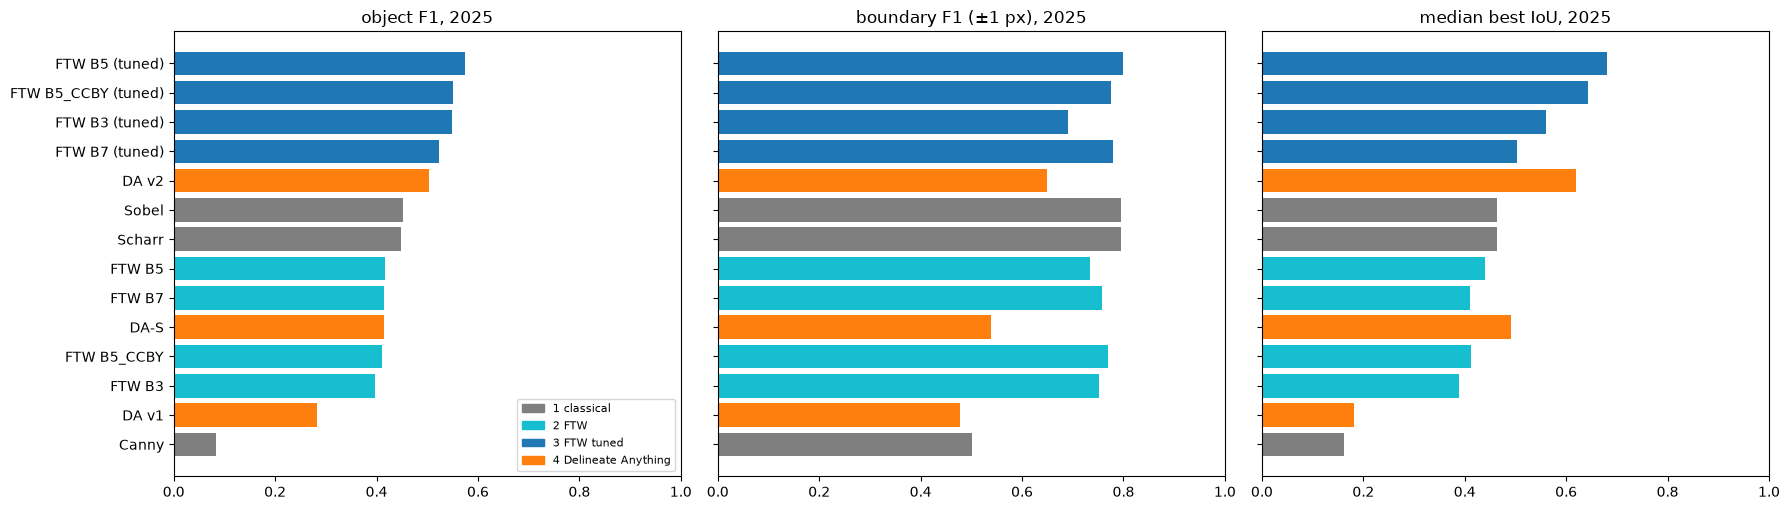

In [ ]:
# Step 9a. All methods on the test year 2025 (FTW settings and Delineate Anything settings were chosen on 2024).
res = table()
test = res[res.year == 2025].sort_values(["kind", "object F1"], ascending=[True, False]).drop(columns="year").set_index(["kind", "method"])
print("Test year 2025:"); print(test.to_string())
both = res.pivot_table(index="method", columns="year", values="object F1").round(3)
print("\nobject F1, selection year 2024 vs test year 2025:"); print(both.sort_values(2025, ascending=False).to_string())

t = res[res.year == 2025].sort_values("object F1")
colors = {"1 classical": "tab:grey", "2 FTW": "tab:cyan", "3 FTW tuned": "tab:blue", "4 Delineate Anything": "tab:orange"}
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2), sharey=True)
for a, col in zip(ax, ["object F1", "boundary F1 (±1 px)", "median best IoU"]):
    a.barh(t.method, t[col], color=[colors[k] for k in t.kind]); a.set_title(f"{col}, 2025"); a.set_xlim(0, 1)
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors), fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Reading the test-year results (2025).**

| Method | Object F1 |
|---|---|
| FTW B5, tuned on 2024 | **0.575** |
| FTW B5 CC-BY, tuned | 0.551 |
| FTW B3, tuned | 0.549 |
| FTW B7, tuned | 0.524 |
| **DA v2** | 0.504 |
| Sobel | 0.453 |
| FTW with the crop-calendar defaults | 0.40-0.42 |
| DA-S | 0.414 |
| DA v1 | 0.282 |
| Canny | 0.084 |

- **Consistency:** the ranking on 2025 matches the selection year (FTW B5 tuned 0.574 → 0.575, DA v2 0.518 → 0.504).
- **Shape agreement:** tuned FTW B5 also has the best median IoU (0.68), meaning the typical reference field is well matched in shape.
- **Pixel boundaries:** Sobel (0.63) and tuned FTW (0.61) lead the exact boundary F1. With a 1-pixel tolerance they tie at 0.80.
- **Speed:** every network needs about 10 s on the GPU for the 883 km² AOI; the classical detectors need about 20 s on the CPU.
- **Absolute values:** all scores stay below 0.6 partly because of the reference itself (Step 2), not only because of the methods.

### What the differences look like


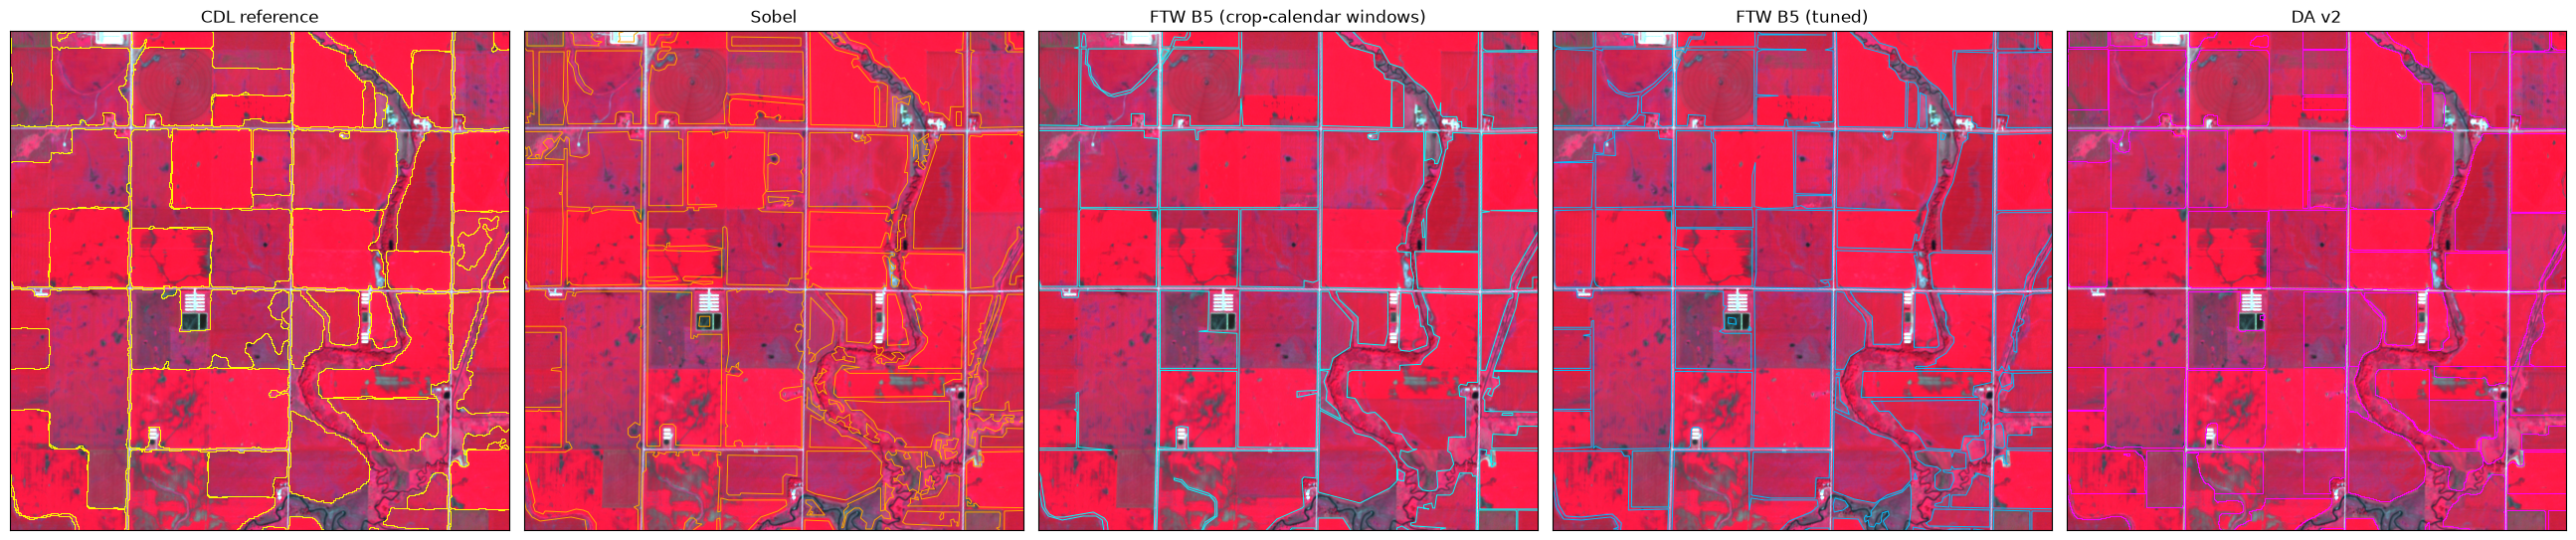

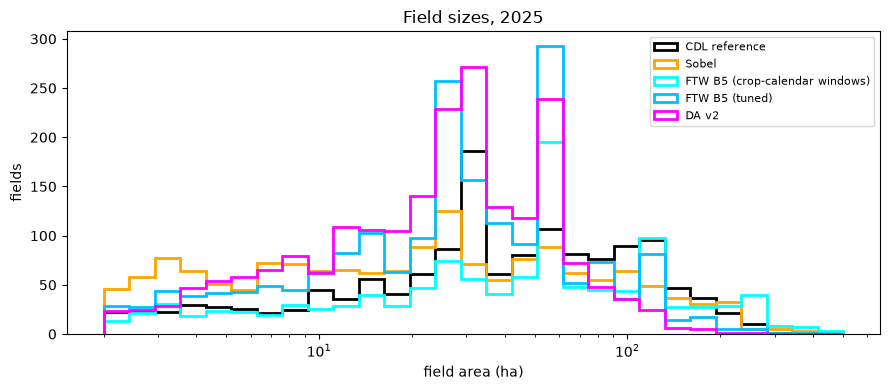

In [ ]:
# Step 9b. What the differences look like: the same 5 x 5 km window, 2025.
BEST_FTW_NAME = max([r for r in RESULTS if r["kind"] == "3 FTW tuned" and r["year"] == 2025], key=lambda r: r["object F1"])["method"]
BEST_DA_NAME = max([r for r in RESULTS if r["kind"] == "4 Delineate Anything" and r["year"] == 2025], key=lambda r: r["object F1"])["method"]
show = [("CDL reference", REF, "yellow"), ("Sobel", MAPS[("Sobel", 2025)], "orange"), ("FTW B5 (crop-calendar windows)", MAPS[("FTW B5", 2025)], "cyan"),
        (BEST_FTW_NAME, MAPS[(BEST_FTW_NAME, 2025)], "deepskyblue"), (BEST_DA_NAME, MAPS[(BEST_DA_NAME, 2025)], "magenta")]
img = false_colour(WIN[MONTH[2025][8]])[Z]
fig, ax = plt.subplots(1, 5, figsize=(26, 5.6))
for a, (t, g, c) in zip(ax, show):
    a.imshow(img, extent=ZEXT)
    g.cx[ZEXT[0]:ZEXT[1], ZEXT[2]:ZEXT[3]].boundary.plot(ax=a, color=c, lw=0.7)
    a.set_xlim(ZEXT[0], ZEXT[1]); a.set_ylim(ZEXT[2], ZEXT[3]); a.set_title(t); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

# field-size distributions (polygons of at least 2 ha in the scored area)
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.logspace(np.log10(2), np.log10(500), 30)
for t, g, c in show:
    ax.hist(g[g.area >= MIN_HA * 1e4].area / 1e4, bins=bins, histtype="step", lw=2, color=c if c != "yellow" else "k", label=t)
ax.set_xscale("log"); ax.set_xlabel("field area (ha)"); ax.set_ylabel("fields"); ax.legend(fontsize=8); ax.set_title("Field sizes, 2025")
plt.tight_layout(); plt.show()

**Reading the maps.**

- **FTW with the crop-calendar windows** draws the road grid cleanly but leaves most road-bounded blocks whole, even where two crops meet.
- **Tuned FTW** adds the internal boundaries between fields.
- **DA v2** outlines fields tightly and finds the internal boundaries too. It leaves narrow gaps along roads and splits some fields along within-field patterns.
- **Sobel** follows every spectral edge, including waterways and patterns inside fields.

**Field sizes.** Tuned FTW and DA v2 show clear peaks at about **16, 32 and 65 ha**. These are 40, 80 and 160 acres: the quarter-quarter, half-quarter and quarter sections of the US Public Land Survey grid on which Iowa fields are laid out. The reference shares the 32 and 65 ha peaks but has more large parcels, because neighbouring fields with the same crops merge in it. Sobel produces many small fragments, and FTW with the defaults many very large polygons.

## Year-to-year stability

Field boundaries change little from one year to the next, even when the crop changes. Matching each method's 2024 polygons against its own 2025 polygons (the same object matching as Step 4) shows how stable a delineation is, without any reference.


In [ ]:
# Step 10. Are the fields stable between 2024 and 2025? Fields rarely change from one year to the next, so a good
# delineation should find nearly the same polygons in both years, whatever crop is grown.
rows = {}
for name in ["Sobel", "FTW B5", BEST_FTW_NAME, BEST_DA_NAME]:
    a, b = MAPS[(name, 2024)], MAPS[(name, 2025)]
    b = b[b.area >= MIN_HA * 1e4].reset_index(drop=True)
    o = match_objects(a, ref=b)
    rows[name] = {"fields 2024": len(a[a.area >= MIN_HA * 1e4]), "fields 2025": len(b),
                  "2024 vs 2025 object F1": o["object F1"], "median best IoU": o["median best IoU"]}
pd.DataFrame(rows).T.round(3)

,fields 2024,fields 2025,2024 vs 2025 object F1,median best IoU
Sobel,1433.0,1586.0,0.412,0.351
FTW B5,1179.0,1146.0,0.792,0.952
FTW B5 (tuned),1715.0,1924.0,0.662,0.724
DA v2,2174.0,2080.0,0.676,0.774


**Reading the stability.**

- **FTW with the defaults** is the most stable between years (object F1 0.79, median IoU 0.95), because it mostly draws the permanent road grid.
- **Tuned FTW (0.66) and DA v2 (0.68)** split fields differently in each year. The boundaries inside a block depend on which crops were grown and on the images.
- **Sobel** is the least stable (0.41).

Stability is not accuracy: a map of road-bounded blocks is perfectly stable and still merges fields. For a field register, the stable road grid and the year-specific internal boundaries could be combined.

## The best map as fiboa GeoParquet

`ed.to_fiboa` adds the fiboa core properties: a unique `id` within the `collection`, `metrics:area` and `metrics:perimeter` computed from the geometry, `determination:method = "auto-imagery"` and `determination:datetime`, the date of the **last image used** (not the processing date). The file can be opened in QGIS or validated with the fiboa tools.


In [ ]:
# Step 11. The best method's 2025 fields as fiboa GeoParquet, with ed.to_fiboa.
best_row = max([r for r in RESULTS if r["year"] == 2025], key=lambda r: r["object F1"])
name = best_row["method"]
fields = MAPS[(name, 2025)]
if name in (BEST_FTW_NAME,):
    last_image = MONTH[2025][BEST_FTW["window B"]]
    details = f"{name}; Sentinel-2 L2A {MONTH[2025][BEST_FTW['window A']]} and {last_image}; ed.detect_fields_ftw"
else:
    last_image = MONTH[2025][BEST_DA["month"]]
    details = f"{name}; Sentinel-2 L2A {last_image}; ed.detect_delineate_anything"
fb = ed.to_fiboa(fields, collection="cornbelt_fields_2025", determination_datetime=last_image, determination_details=details)
path = OUT / "cornbelt_fields_2025_fiboa.parquet"
fb.to_parquet(path)
print(f"best method on 2025: {name} (object F1 {best_row['object F1']:.3f}); {len(fb):,} fields written to {path.name}")
print(f"total field area {fb['metrics:area'].sum() / 1e4:,.0f} ha (reference parcels: {REF.area.sum() / 1e4:,.0f} ha); "
      f"median {fb['metrics:area'].median() / 1e4:.1f} ha")
fb.drop(columns="geometry").head()

best method on 2025: FTW B5 (tuned) (object F1 0.575); 2,191 fields written to cornbelt_fields_2025_fiboa.parquet
total field area 76,014 ha (reference parcels: 77,672 ha); median 26.8 ha


,id,collection,field_id,score,area_m2,perimeter_m,metrics:area,metrics:perimeter,determination:method,determination:datetime,determination:details,category
0,1,cornbelt_fields_2025,3,0.996584,25050.0,2069.957047,25050.0,2069.957047,auto-imagery,2025-10-10 00:00:00+00:00,FTW B5 (tuned); Sentinel-2 L2A 2025-07-14 and ...,[other]
1,2,cornbelt_fields_2025,4,0.999986,15400.0,851.231056,15400.0,851.231056,auto-imagery,2025-10-10 00:00:00+00:00,FTW B5 (tuned); Sentinel-2 L2A 2025-07-14 and ...,[other]
2,3,cornbelt_fields_2025,5,0.996724,40200.0,1735.404225,40200.0,1735.404225,auto-imagery,2025-10-10 00:00:00+00:00,FTW B5 (tuned); Sentinel-2 L2A 2025-07-14 and ...,[other]
3,4,cornbelt_fields_2025,6,0.999605,22600.0,852.327001,22600.0,852.327001,auto-imagery,2025-10-10 00:00:00+00:00,FTW B5 (tuned); Sentinel-2 L2A 2025-07-14 and ...,[other]
4,5,cornbelt_fields_2025,7,0.992344,23300.0,802.593361,23300.0,802.593361,auto-imagery,2025-10-10 00:00:00+00:00,FTW B5 (tuned); Sentinel-2 L2A 2025-07-14 and ...,[other]


The best method on the test year, **FTW B5 with the 2024-selected settings**, gives 2 191 fields of at least 500 m² over the whole AOI. Their total area is 76 014 ha, against 77 672 ha of reference parcels, with a median field of 26.8 ha.

`determination:datetime` is 10 October 2025 (window B), and `determination:details` names the model and the two image dates. The file is `outputs/field_edge_sentinel2/cornbelt_fields_2025_fiboa.parquet`.

## Discussion

- **Settings matter more than model size.** The windows and the up-sampling factor moved FTW B5 from object F1 0.42 to 0.58. The four FTW models differ by at most 0.05 under the same settings, and B7 is not better than B5 here. The crop-calendar windows of the FTW CLI (May and October) are not ideal in the Corn Belt: in May both crops are bare soil, and July shows the crop contrast.
- **The licence-clean model costs little.** FTW B5 CC-BY reaches 0.551 against 0.575 for the standard B5.
- **FTW and Delineate Anything make opposite errors.** FTW, a semantic model on two dates, **merges** neighbouring fields when it sees no boundary between them. Delineate Anything, an instance model on one date, **splits** fields along patterns inside them. DA v2 with a single August image comes within 0.07 of tuned FTW and clearly beats FTW at its defaults; DA v1 is not usable on this imagery.
- **Classical gradients are a strong pixel baseline but a poor field map.** Sobel matches the networks on boundary pixels, because the reference boundaries are crop edges, but its fields leak and fragment.
- **The reference limits the absolute scores.** CDL parcels merge neighbours with the same crops and inherit CDL edge errors. The best method's median IoU of 0.68 shows that most fields are matched well in shape, even though fewer than 60 % reach the IoU ≥ 0.5 one-to-one match.
- **Next steps.**
  - Combine the two families, e.g. the FTW field mask with Delineate Anything instances, or the stable road grid with year-specific internal boundaries.
  - Fine-tune on a sample of digitised local parcels.
  - Evaluate against surveyed or digitised field boundaries.

### Limitations

- **The reference is derived from the CDL**, a 10 m per-pixel crop classification. Neighbouring fields with the same crop in both years merge into one parcel, crop strips inside a field split it, and field edges are only as precise as the CDL. Scores measure agreement with this reference, not with surveyed boundaries.
- **One landscape.** Large, rectangular corn and soybean fields separated by roads are among the easiest cases for field delineation; smallholder landscapes (see 09_10_03) are much harder.
- **Released models, no fine-tuning.** Both FTW and Delineate Anything could be fine-tuned on local parcels; that would change the ranking.
- **Settings matter.** FTW's windows and Delineate Anything's date and scale were chosen on one other year; other years or regions may need other choices.
- **Licences.** FTW standard models and their output carry non-commercial training data (use the `_CCBY` models for commercial work); Delineate Anything is AGPL-3.

### Summary

- **Pipeline.** `geolattice.rsense.edge_detectors` runs the released FTW checkpoints (`ftw_models`, `load_ftw_model`, `ftw_stack`, `detect_fields_ftw`) and Delineate Anything (`load_delineate_anything`, `detect_delineate_anything`) on Sentinel-2. It scores them with `edge_metrics` and object matching, and writes fiboa with `to_fiboa`.
- **Results on the test year 2025**, against CDL-derived parcels: FTW B5 with settings chosen on 2024 is best (object F1 0.575). FTW B5 CC-BY (0.551) and DA v2 (0.504) follow, then Sobel (0.453). FTW with the crop-calendar defaults reaches only 0.40-0.42.
- **What to tune for FTW:** the up-sampling factor (1 for large fields) and the windows (a mid-season window A) matter more than the model size.
- **Error types:** FTW merges neighbouring fields and Delineate Anything splits them.
- **Speed:** both run in about 10 s per 883 km² on one GPU.

### References

- Kerner, H., Chaudhari, S., Ghosh, A., Robinson, C., Ahmad, A., Choi, E., et al. (2025). Fields of The World: a machine learning benchmark dataset for global agricultural field boundary segmentation. *Proceedings of the AAAI Conference on Artificial Intelligence*. Code: <https://github.com/fieldsoftheworld/ftw-baselines>.
- Lavreniuk, M., Kussul, N., Shelestov, A., Yailymov, B., Salii, Y., Kuzin, V., & Szantoi, Z. (2025). Delineate Anything: resolution-agnostic field boundary delineation on satellite imagery. arXiv:2504.02534.
- fiboa: Field Boundaries for Agriculture, specification v0.3. <https://fiboa.org>.
- Boryan, C., Yang, Z., Mueller, R., & Craig, M. (2011). Monitoring US agriculture: the USDA NASS Cropland Data Layer program. *Geocarto International*, 26(5), 341-358.
- Canny, J. (1986). A computational approach to edge detection. *IEEE TPAMI*, 8(6), 679-698.
